Random Forest Accuracy : 0.9931818181818182
Accuracy :  0.9454545454545454
Deciscion Accuracy tree :  0.9818181818181818
N : 0.11051399572555433
P : 0.152699225176399
K : 0.1774492740038144
temperature : 0.08104518374831679
humidity : 0.19985144105707883
ph : 0.05325212937021775
rainfall : 0.22518875091861892
Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall'], dtype='object')
[0.110514   0.15269923 0.17744927 0.08104518 0.19985144 0.05325213
 0.22518875]


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


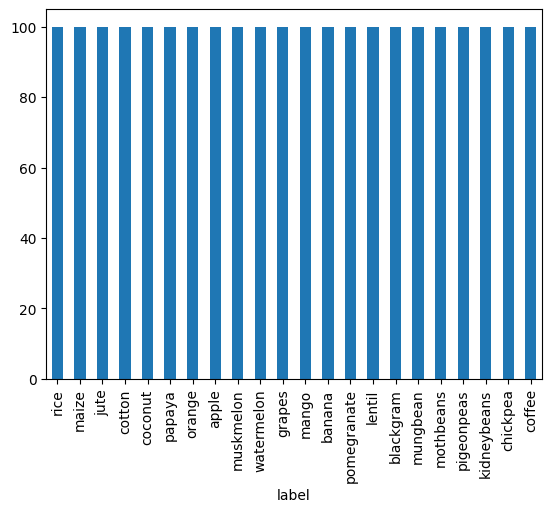

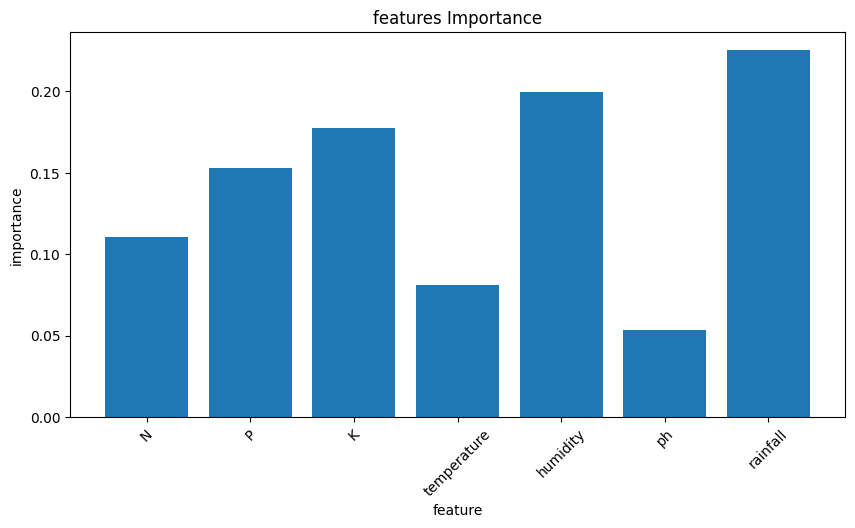

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


'rice'

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import joblib

df =pd.read_csv("../data/Crop_recommendation.csv")
tree_model = DecisionTreeClassifier()
x = df.drop("label",axis=1)
y = df["label"]
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state = 42
)


frost_model = RandomForestClassifier()
frost_model.fit(x_train,y_train)
frost_pred = frost_model.predict(x_test)
frost_accuracy = accuracy_score(y_test,frost_pred)
print("Random Forest Accuracy :" ,frost_accuracy)

model = LogisticRegression(max_iter=1000)
model.fit(x_train , y_train)
y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test,y_pred)
print("Accuracy : ",accuracy)
tree_model.fit(x_train,y_train)
tree_pred = tree_model.predict(x_test)
tree_accuracy = accuracy_score(y_test,tree_pred)
print("Deciscion Accuracy tree : ", tree_accuracy)
cm = confusion_matrix(y_test,tree_pred)
#print(cm)

importance = frost_model.feature_importances_

features = x.columns

for feature , score in zip(features,importance):
    print(feature ,":",score)
print(features)
print(importance)

df["label"].value_counts().plot(kind="bar")
plt.xticks(rotation = 90)
plt.show()
x.head()
y.head()
x_train.shape
x_test.shape
plt.figure(figsize=(10,5))
plt.bar(features,importance)

plt.title("features Importance")
plt.xlabel("feature")
plt.ylabel("importance")
plt.xticks(rotation= 45)
plt.show()
joblib.dump(frost_model,"../models/random_frost.pkl")
loaded_model=joblib.load("../models/random_frost.pkl")

def predict_crop(N,P,K,teampture,humidity,ph,rainfall):
    sample =[[N,P,K,teampture,humidity,ph,rainfall]]
    prediction=loaded_model.predict(sample)
    return prediction[0]

predict_crop(90, 42, 43, 20.87, 82.00, 6.5, 202.9)


